# Proyecto Final: Detección de Fraude Bancario con KDD
**Curso:** SINF-633 Análisis Exploratorio de Datos  Universidad Cenfotec
**Dataset:** 'transacciones_bancarias.csv'
**Herramientas:** Python (pandas, scikit-learn, seaborn) en Google Colab, con apoyo de Claude (IA) para estructurar el código y redactar. Las decisiones y conclusiones son mías.

**Pregunta central:** Qué patrones permiten distinguir transacciones bancarias legítimas de fraudulentas, y cómo puede el banco operacionalizar esos patrones para reducir pérdidas sin degradar la experiencia del cliente legítimo?


## 0. Librerías

In [ ]:
import os # logra que se trabaje en el sistema operativo del sistema
import numpy as np # cálculos numéricos
import pandas as pd # tablas de datos
import matplotlib.pyplot as plt # gráficos
import seaborn as sns # gráficos estadísticos (heatmap)

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.cluster import KMeans, DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, confusion_matrix, silhouette_score)

import warnings
warnings.filterwarnings('ignore')  # oculta avisos que no afectan los resultados
os.makedirs('figuras', exist_ok=True) # carpeta para guardar los gráficos del informe

---
# Etapa 1 · Selección
### 1.1 Cargar el dataset


In [ ]:
df = pd.read_csv('/content/sample_data/transacciones_bancarias.csv', parse_dates=['fecha_hora'])
print(df.shape)
df.head() #Usamos `parse_dates` para que `fecha_hora` sea una fecha y no texto (así podemos sacar la hora o más bien el sistema puede leerla como hora).

(5000, 11)


,id_transaccion,fecha_hora,id_cliente,edad_cliente,antiguedad_cuenta_meses,tipo_transaccion,monto,canal,region,estado_transaccion,es_fraude
0,1,2024-08-29 17:11:00,845,59.0,134,Depósito,277.26,Teléfono,Alajuela,Completada,0
1,2,2024-07-11 23:18:00,1422,41.0,189,Retiro,21.38,Web,Alajuela,Completada,0
2,3,2024-05-01 13:13:00,41,28.0,8,Depósito,35.65,ATM,San José,Completada,0
3,4,2024-08-05 15:59:00,1475,56.0,121,Pago servicios,271.13,Web,Alajuela,Completada,0
4,5,2024-12-09 05:48:00,1462,18.0,110,Retiro,290.32,ATM,San José,Completada,0


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 11 columns):
 #   Column                   Non-Null Count  Dtype         
---  ------                   --------------  -----         
 0   id_transaccion           5000 non-null   int64         
 1   fecha_hora               5000 non-null   datetime64[ns]
 2   id_cliente               5000 non-null   int64         
 3   edad_cliente             4929 non-null   float64       
 4   antiguedad_cuenta_meses  5000 non-null   int64         
 5   tipo_transaccion         5000 non-null   object        
 6   monto                    5000 non-null   float64       
 7   canal                    4941 non-null   object        
 8   region                   4921 non-null   object        
 9   estado_transaccion       5000 non-null   object        
 10  es_fraude                5000 non-null   int64         
dtypes: datetime64[ns](1), float64(2), int64(4), object(4)
memory usage: 429.8+ KB


### 1.2 Tipos de variables y cuáles usamos

- **Numéricas:** edad_cliente, antiguedad_cuenta_meses y monto. Se usan como dato numero
- **Categóricas:** tipo_transaccion, canal y region. Se usan
- **estado_transaccion** (categórica): No lo usamos en el modelo porque el sistema lee el estado que se conoce despues de procesar la transaccion, el no necesita usar estos datos para aprender el enfoque que le estamos dando, aunque si los usamos para hacer las exploraciones en Apriori que solo usa datos del pasado o historicos.
- **Fecha:** fecha_hora. Lo usamos para que el sistema pueda entender la fecha como dato, y no como frase, tambien nos ayuda a diferenciar entre dia y noche.
- **Identificadores:** id_transaccion e id_cliente. No se usan porque solo son códigos, le hacen ruido al sistema y le enseñan por ID y no por comportamiento
- **Objetivo:** es_fraude, los identificamos como 1 = fraude, 0 = No Fraude.

### 1.3 Seleccionar columnas relevantes

In [ ]:
df = df.drop(columns=['id_transaccion', 'id_cliente'])  # Eliminamos IDs
print(df.columns.tolist())

['fecha_hora', 'edad_cliente', 'antiguedad_cuenta_meses', 'tipo_transaccion', 'monto', 'canal', 'region', 'estado_transaccion', 'es_fraude']


### 1.4 Tasa global de fraude

es_fraude
0    4891
1     109
Name: count, dtype: int64
Tasa de fraude: 2.18%


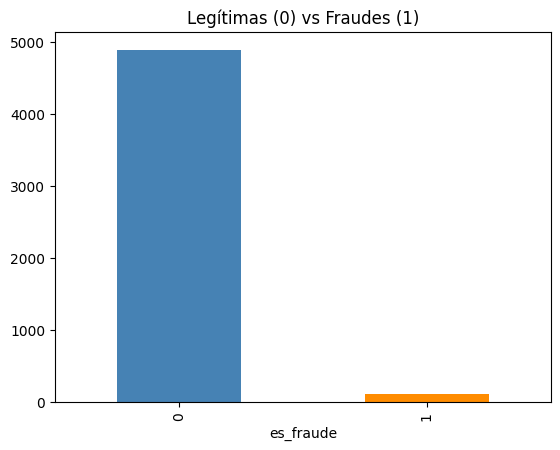

In [ ]:
print(df['es_fraude'].value_counts())  # aca contamos cuantos fraudes designados como  1, o 0 para transacciones legitima, y los graficamos
print(f"Tasa de fraude: {df['es_fraude'].mean():.2%}")  # proporción de fraudes

df['es_fraude'].value_counts().plot(kind='bar', color=['steelblue', 'darkorange'])
plt.title('Legítimas (0) vs Fraudes (1)')
plt.show() #Nota: estos datos ya vienen incluidos en el DF, son datos historicos(Datos: es_fraude).

**Reflexión sobre el desbalance:** solo el 2.18 % de las transacciones son fraude, aproximadamente 45 legitimas por cada fraude. Esto es un problema, usando un modelo que diga siempre “legítima” acertaría el 97.8 % de las veces sin detectar ningún fraude, puesto que lee las reales pero no avisa sobre fraudes, diria que todas son legitimas pero no todas lo son. Por eso no podemos confiar solo en la accuracy para evaluar los modelos o la informacion como tal, por eso decidi evaluar los modelos con recall, precision, F1 y AUC y no solo con accuracy.

---
##Etapa 2. Preprocesamiento
####2.1 Valores nulos

In [ ]:
nulos = pd.DataFrame({'cantidad': df.isna().sum(),                  # nulos por columna
                      'porcentaje': (df.isna().mean() * 100).round(2)})
nulos[nulos['cantidad'] > 0]

,cantidad,porcentaje
edad_cliente,71,1.42
canal,59,1.18
region,79,1.58


**Estrategia:**
- **edad_cliente**-Mediana: la usamos porque es  numérica y la mediana no se afecta por valores extremos a diferencia de un promedio.
- **canal** y **region** - flag: nueva categoría "Desconocido", para no inventar un valor que no sabemos y no es posible determinar.

In [ ]:
df['edad_cliente'] = df['edad_cliente'].fillna(df['edad_cliente'].median())  # mediana
df['canal'] = df['canal'].fillna('Desconocido')   # flag
df['region'] = df['region'].fillna('Desconocido') # flag
print('Nulos restantes:', df.isna().sum().sum())

Nulos restantes: 0


### 2.2 Outliers con IQR (k = 1.5)
Es outlier todo valor fuera de [Q1 − 1.5 * IQR, Q3 + 1.5 * IQR]. Comparamos la tasa de fraude dentro y fuera de los outliers.

In [ ]:
for col in ['edad_cliente', 'antiguedad_cuenta_meses', 'monto']:
    q1, q3 = df[col].quantile([0.25, 0.75])   # cuartiles
    iqr = q3 - q1   # rango intercuartílico
    outlier = (df[col] < q1 - 1.5 * iqr) | (df[col] > q3 + 1.5 * iqr)   # True si es outlier
    print(f"{col}: {outlier.sum()} outliers | fraude en outliers: {df.loc[outlier, 'es_fraude'].mean():.2%}"
          f" | fraude en no outliers: {df.loc[~outlier, 'es_fraude'].mean():.2%}")

edad_cliente: 18 outliers | fraude en outliers: 0.00% | fraude en no outliers: 2.19%
antiguedad_cuenta_meses: 0 outliers | fraude en outliers: nan% | fraude en no outliers: 2.18%
monto: 584 outliers | fraude en outliers: 13.87% | fraude en no outliers: 0.63%


**Resultado: conservamos los outliers.** Los outliers de 'monto' tienen aprox 13.9% de fraude contra aprox 0.6% del resto (aproximadamente a 22 veces más fraudes presentes en los outliers). Eliminarlos sería borrar los casos que queremos detectar. En vez de eliminarlos, reducimos su efecto con el logaritmo (2.4). (En 'antiguedad_cuenta_meses' no hay outliers, por eso su tasa aparece vacía.)

### 2.3 Duplicados

In [ ]:
print('Duplicados encontrados:', df.duplicated().sum())
df = df.drop_duplicates() # eliminamos los duplicados que se encuentren
print('Filas después:', len(df))

Duplicados encontrados: 0
Filas después: 5000


No hay duplicados.


### 2.4 Transformación 'np.log1p()' del monto
El monto es muy asimétrico (muchas transacciones pequeñas y pocas gigantes). El logaritmo comprime los valores grandes.

Asimetría antes : 8.66
Asimetría después: 1.64


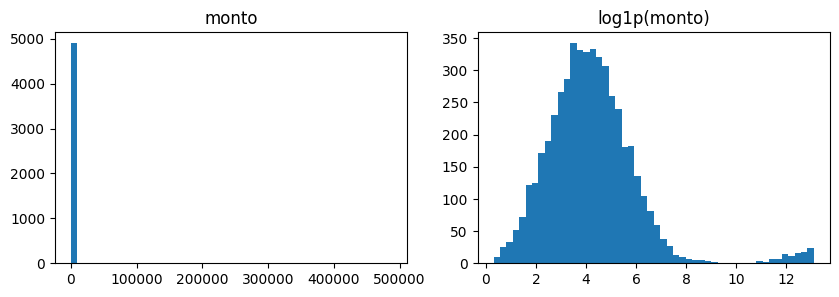

In [ ]:
df['monto_log'] = np.log1p(df['monto'])                # log(1 + monto)
print('Asimetría antes :', round(df['monto'].skew(), 2))
print('Asimetría después:', round(df['monto_log'].skew(), 2))

fig, ax = plt.subplots(1, 2, figsize=(10, 3))
ax[0].hist(df['monto'], bins=50);     ax[0].set_title('monto')
ax[1].hist(df['monto_log'], bins=50); ax[1].set_title('log1p(monto)')
plt.show()

---
# Etapa 3 · Transformación
### 3.1 Variables derivadas
- 'monto_log': ya creada en 2.4
- 'hora_dia': hora de la transacción (0–23)
- 'es_noche': 1 si es entre las 22:00 y las 05:59

In [ ]:
df['hora_dia'] = df['fecha_hora'].dt.hour                                    # hora
df['es_noche'] = ((df['hora_dia'] >= 22) | (df['hora_dia'] < 6)).astype(int) # 1 = noche
df[['fecha_hora', 'hora_dia', 'es_noche', 'monto', 'monto_log']].head()

,fecha_hora,hora_dia,es_noche,monto,monto_log
0,2024-08-29 17:11:00,17,0,277.26,5.628556
1,2024-07-11 23:18:00,23,1,21.38,3.108168
2,2024-05-01 13:13:00,13,0,35.65,3.601413
3,2024-08-05 15:59:00,15,0,271.13,5.606280
4,2024-12-09 05:48:00,5,1,290.32,5.674422


### 3.2 Las variables nuevas separan el fraude?

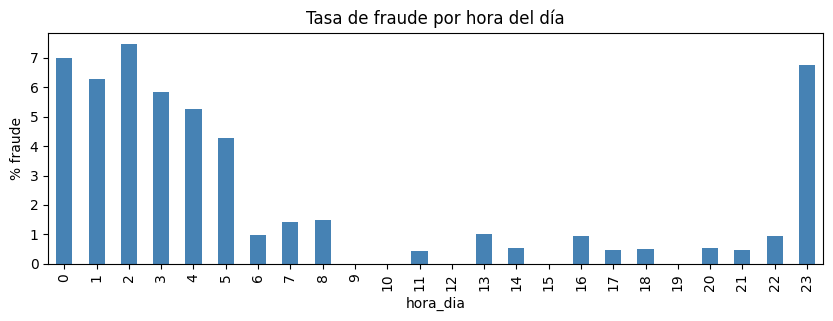

In [ ]:
fraude_hora = df.groupby('hora_dia')['es_fraude'].mean() * 100     # % de fraude por hora
fraude_hora.plot(kind='bar', figsize=(10, 3), color='steelblue')
plt.ylabel('% fraude'); plt.title('Tasa de fraude por hora del día')
plt.savefig('figuras/fraude_por_hora.png', bbox_inches='tight')
plt.show()

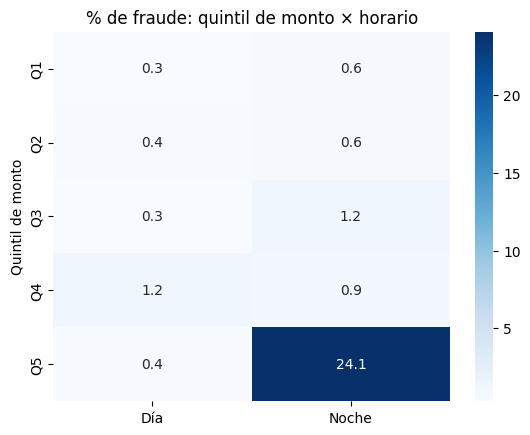

In [ ]:
# Tasa de fraude (%) según quintil de monto (5 grupos) y si es de noche
quintil = pd.qcut(df['monto'], 5, labels=['Q1', 'Q2', 'Q3', 'Q4', 'Q5'])
tabla = pd.crosstab(quintil, df['es_noche'], values=df['es_fraude'], aggfunc='mean') * 100
tabla.columns = ['Día', 'Noche']

sns.heatmap(tabla, annot=True, fmt='.1f', cmap='Blues')
plt.title('% de fraude: quintil de monto × horario'); plt.ylabel('Quintil de monto')
plt.savefig('figuras/monto_x_noche.png', bbox_inches='tight')
plt.show()

**Lo encontrado:** el fraude se concentra en **alto monto de transaccion + noche**: en el quintil más alto de monto durante la noche,  aprox. 24% de las transacciones son fraude. En el resto de combinaciones no pasa de 1.5%.

### 3.3 Matriz de correlación (pares con |r| > 0.8)

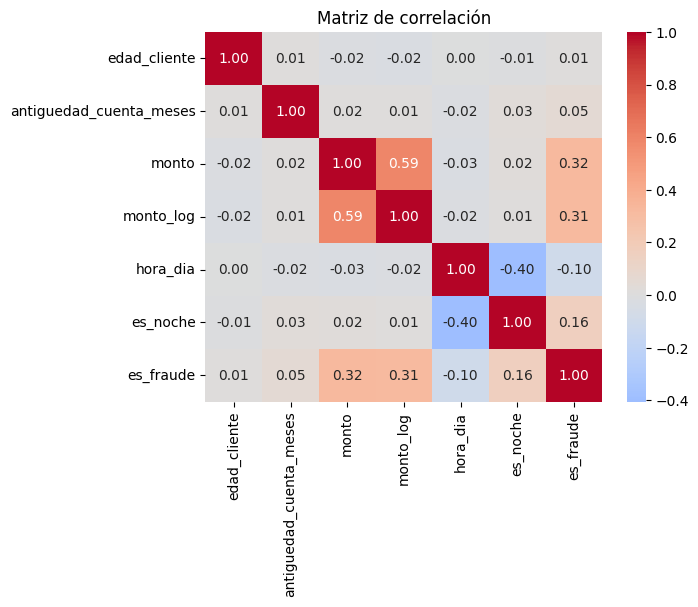

In [ ]:
cols = ['edad_cliente', 'antiguedad_cuenta_meses', 'monto', 'monto_log', 'hora_dia', 'es_noche', 'es_fraude']
corr = df[cols].corr()  # correlación de Pearson

sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Matriz de correlación')
plt.show()

# pares con |r| > 0.8 (sin repetir ni comparar una variable consigo misma)
for i in range(len(cols)):
    for j in range(i + 1, len(cols)):
        if abs(corr.iloc[i, j]) > 0.8:
            print(cols[i], '-', cols[j], round(corr.iloc[i, j], 2))

**Comentario:** ningún par supera r(coeficiente de correlacion pearson) > 0.8, así que no hay multicolinealidad fuerte. El par más alto es 'monto'–'monto_log' (0.59) porque una sale de la otra, en el modelo usamos  'monto_log'. La informacion más relacionada con el fraude son 'monto_log' y 'es_noche' que son las que tienen más correlacion con es_fraude (0.31 y 0.16).

### 3.4 División train/test (80/20, stratify, semilla 42)

In [ ]:
num_cols = ['edad_cliente', 'antiguedad_cuenta_meses', 'monto_log', 'hora_dia', 'es_noche']
cat_cols = ['tipo_transaccion', 'canal', 'region']

X = df[num_cols + cat_cols] # variables
y = df['es_fraude'] # objetivo

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
print('Train:', X_train.shape, '/ fraudes:', y_train.sum())
print('Test :', X_test.shape, '/ fraudes:', y_test.sum())

Train: (4000, 8) / fraudes: 87
Test : (1000, 8) / fraudes: 22


### 3.5 Pipeline: OneHotEncoder y StandardScaler
- 'OneHotEncoder(drop='first')' convierte las categóricas en columnas 0-1 y elimina la primera para evitar redundancias.
- 'StandardScaler' deja las numéricas con media 0 y desviación 1.
- El Pipeline se ajusta ('fit') solo con train, así el modelo no ve información del test que pueda intrepretar para su aprendizaje, al final tiene que saber responder sin saber respuestas.

In [ ]:
preprocesador = ColumnTransformer([
    ('num', StandardScaler(), num_cols),
    ('cat', OneHotEncoder(drop='first', handle_unknown='ignore'), cat_cols)
])
pipeline = Pipeline([('preprocesamiento', preprocesador)])

X_train_t = pipeline.fit_transform(X_train) # aprende media y desviación de train
X_test_t = pipeline.transform(X_test) # responde al test
print('Columnas después de transformar:', X_train_t.shape[1])

Columnas después de transformar: 20


---
# Etapa 4, Minería de datos
## A. No supervisado
Usamos 5 variables numéricas escaladas. No incluimos las dummies porque K-Means y DBSCAN miden distancias, y las columnas 0-1 distorsionan esa distancia.

In [ ]:
vars_cluster = ['monto_log', 'hora_dia', 'es_noche', 'edad_cliente', 'antiguedad_cuenta_meses']
X_cluster = StandardScaler().fit_transform(df[vars_cluster]) # datos escalados para clustering

### 4.1 K-Means (k = 2 a 10): codo y silueta

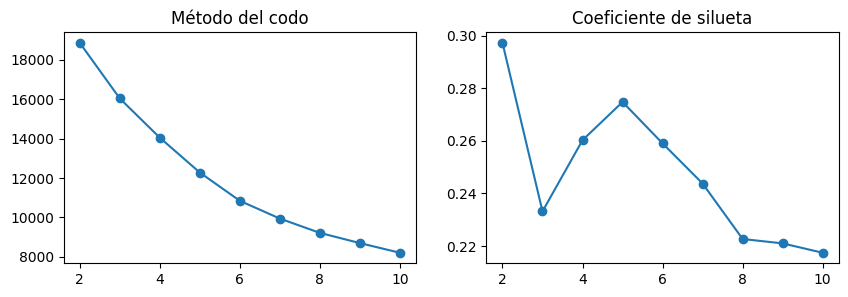

[np.float64(0.297), np.float64(0.233), np.float64(0.26), np.float64(0.275), np.float64(0.259), np.float64(0.244), np.float64(0.223), np.float64(0.221), np.float64(0.217)]


In [ ]:
inercias, siluetas = [], []
for k in range(2, 11):
    km = KMeans(n_clusters=k, random_state=42, n_init=10).fit(X_cluster)
    inercias.append(km.inertia_)  # para el codo
    siluetas.append(silhouette_score(X_cluster, km.labels_)) # para la silueta

fig, ax = plt.subplots(1, 2, figsize=(10, 3))
ax[0].plot(range(2, 11), inercias, marker='o'); ax[0].set_title('Método del codo')
ax[1].plot(range(2, 11), siluetas, marker='o'); ax[1].set_title('Coeficiente de silueta')
plt.show()
print([round(s, 3) for s in siluetas])

**k elegido = 5.** La silueta más alta es k = 2 (0.297), pero solo separa día de noche. k = 5 coincide con el codo, es un máximo local de silueta (0.275) y separa un grupo de montos muy altos con mucho fraude.

In [ ]:
df['cluster'] = KMeans(n_clusters=5, random_state=42, n_init=10).fit_predict(X_cluster)
df.groupby('cluster').agg(transacciones=('es_fraude', 'size'),
                          monto_mediano=('monto', 'median'),
                          hora_promedio=('hora_dia', 'mean'),
                          tasa_fraude=('es_fraude', 'mean')).round(3)

,transacciones,monto_mediano,hora_promedio,tasa_fraude
cluster,,,,
0,1215,57.84,2.570,0.035
1,1645,55.06,13.531,0.003
2,116,211331.52,10.922,0.319
3,412,55.69,22.493,0.029
4,1612,53.03,13.446,0.008


Un cluster pequeño (116 transacciones) con montos muy altos tiene 32% de fraude, casi 15 veces el promedio.

### 4.2 DBSCAN
- `min_samples = 10` (regla práctica: 2 × número de variables = 2 × 5).
- `eps = 0.8`, elegido con el gráfico de k-distancias (donde la curva empieza a subir fuerte).

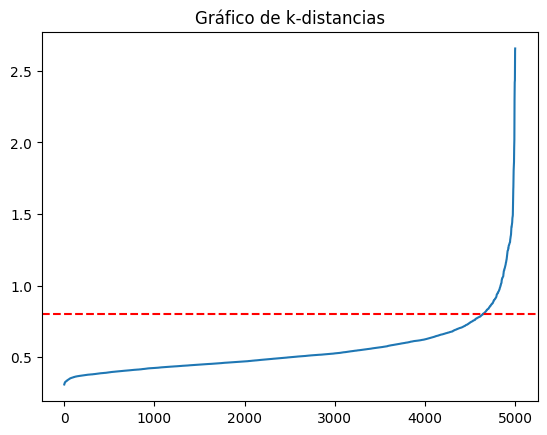

In [ ]:
distancias, _ = NearestNeighbors(n_neighbors=10).fit(X_cluster).kneighbors(X_cluster)
plt.plot(np.sort(distancias[:, -1])) #distancia al 10mo vecino, ordenada
plt.axhline(0.8, color='red', linestyle='--')
plt.title('Gráfico de k-distancias'); plt.show()

In [ ]:
df['dbscan'] = DBSCAN(eps=0.8, min_samples=10).fit_predict(X_cluster)
anomalias = df['dbscan'] == -1                                      # -1 = anomalía
print('Anomalías:', anomalias.sum())
print(f"% de anomalías que son fraude: {df.loc[anomalias, 'es_fraude'].mean():.2%}")
print('Fraudes capturados:', df.loc[anomalias, 'es_fraude'].sum(), 'de', df['es_fraude'].sum())

Anomalías: 149
% de anomalías que son fraude: 26.85%
Fraudes capturados: 40 de 109


DBSCAN marca 149 anomalías y 27% son fraude (12 veces el promedio), pero solo captura 40 de 109 fraudes. Sirve como alerta extra, no como detector principal.

### 4.3 PCA a 2 y 3 componentes

In [ ]:
pca2 = PCA(n_components=2).fit(X_cluster)
pca3 = PCA(n_components=3).fit(X_cluster)
print('Varianza explicada 2 componentes:', pca2.explained_variance_ratio_.round(3), '= total', round(pca2.explained_variance_ratio_.sum(), 3))
print('Varianza explicada 3 componentes:', pca3.explained_variance_ratio_.round(3), '= total', round(pca3.explained_variance_ratio_.sum(), 3))
X_pca2 = pca2.transform(X_cluster)
X_pca3 = pca3.transform(X_cluster)

Varianza explicada 2 componentes: [0.282 0.204] = total 0.486
Varianza explicada 3 componentes: [0.282 0.204 0.2  ] = total 0.687


## B. Supervisado
Cada modelo es un Pipeline (preprocesamiento + modelo).

In [ ]:
modelos = {
    'Regresión Logística': LogisticRegression(class_weight='balanced', max_iter=1000),
    'Random Forest': RandomForestClassifier(class_weight='balanced', random_state=42),
    'Gradient Boosting': GradientBoostingClassifier(random_state=42),
}

resultados, predicciones, probabilidades = [], {}, {}
for nombre, modelo in modelos.items():
    pipe = Pipeline([('preprocesamiento', preprocesador), ('modelo', modelo)])
    pipe.fit(X_train, y_train)  # entrena con train
    pred = pipe.predict(X_test)   # predice 0/1
    prob = pipe.predict_proba(X_test)[:, 1]  # probabilidad de fraude
    predicciones[nombre], probabilidades[nombre] = pred, prob
    if nombre == 'Random Forest':
        rf_pipe = pipe   # lo guardamos para la importancia de variables
    resultados.append([nombre, accuracy_score(y_test, pred), precision_score(y_test, pred),
                       recall_score(y_test, pred), f1_score(y_test, pred), roc_auc_score(y_test, prob)])

metricas = pd.DataFrame(resultados, columns=['Modelo', 'Accuracy', 'Precision', 'Recall', 'F1', 'AUC-ROC'])
metricas.round(3)

,Modelo,Accuracy,Precision,Recall,F1,AUC-ROC
0,Regresión Logística,0.834,0.100,0.818,0.178,0.906
1,Random Forest,0.994,1.000,0.727,0.842,0.894
2,Gradient Boosting,0.993,0.895,0.773,0.829,0.889


**Lectura (test: 1 000 transacciones, 22 fraudes):**
- Regresión Logística detecta el 82% de los fraudes (18 de 22), pero su precision es de 10%, o sea de 180 alertas solo 18 son fraude y molestaria a 162 clientes legitimos.
- Random Forest detecta el 73% (16 de 22) pero con precision de 100%, todas sus alertas son fraude real. Con el umbral que probamos en 5.5 sube a 18 de 22 molestando solo a 1 cliente.
- Gradient Boosting queda parecido al Random Forest (77% de recall y 89.5% de precision).
- La Regresión Logística tiene el AUC más alto (0.906) porque ordena bien el riesgo en general, pero con el umbral normal lanza demasiadas alertas, por eso elegimos el Random Forest, que es el que mejor equilibra atrapar fraudes y no molestar al cliente.
- El Random Forest funciona mejor porque el fraude es una **combinación** (monto alto **y** noche), y los árboles captan esas combinaciones mejor que un modelo lineal.

### 4.4 Reglas de asociación con Apriori

In [ ]:
from mlxtend.frequent_patterns import apriori, association_rules
warnings.filterwarnings('ignore')

canasta = pd.DataFrame({
    'tipo': df['tipo_transaccion'], 'canal': df['canal'], 'region': df['region'],
    'estado': df['estado_transaccion'],
    'horario': np.where(df['es_noche'] == 1, 'Noche', 'Dia'),
    'monto': np.where(df['monto'] >= df['monto'].quantile(0.8), 'Alto', 'Normal'),
    'resultado': np.where(df['es_fraude'] == 1, 'FRAUDE', 'Legitima'),
})
canasta = pd.get_dummies(canasta).astype(bool) # una columna True/False por categoría

frecuentes = apriori(canasta, min_support=0.01, use_colnames=True)
reglas = association_rules(frecuentes, metric='lift', min_threshold=1.5)
reglas_fraude = reglas[reglas['consequents'] == {'resultado_FRAUDE'}]
reglas_fraude.sort_values('lift', ascending=False).head(5)[['antecedents', 'consequents', 'support', 'confidence', 'lift']]

,antecedents,consequents,support,confidence,lift
20,"(estado_Completada, monto_Alto, horario_Noche)",(resultado_FRAUDE),0.0146,0.255245,11.708475
14,"(horario_Noche, monto_Alto)",(resultado_FRAUDE),0.0160,0.240964,11.053388
9,"(estado_Completada, monto_Alto)",(resultado_FRAUDE),0.0152,0.091566,4.200287
3,(monto_Alto),(resultado_FRAUDE),0.0166,0.083000,3.807339
5,"(estado_Completada, horario_Noche)",(resultado_FRAUDE),0.0166,0.058533,2.685007


Las reglas más fuertes hacia fraude combinan **monto alto + noche** (lift aprox de 11). Monto alto solo tiene lift aproximado de 3.8: la combinación es lo que nos da de  resultado como fraude.

---
# Etapa 5, Interpretación y visualización
### 5.1 Matrices de confusión

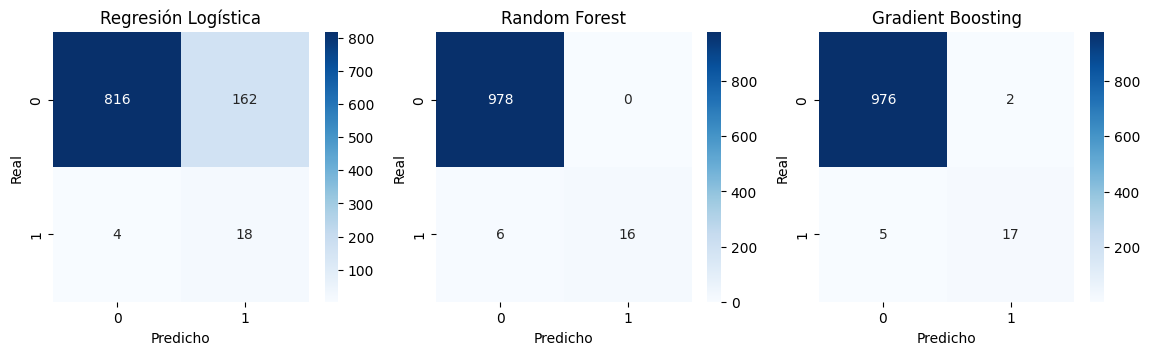

In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(14, 3.5))
for i, (nombre, pred) in enumerate(predicciones.items()):
    sns.heatmap(confusion_matrix(y_test, pred), annot=True, fmt='d', cmap='Blues', ax=ax[i])
    ax[i].set_title(nombre); ax[i].set_xlabel('Predicho'); ax[i].set_ylabel('Real')
plt.savefig('figuras/matrices_confusion.png', bbox_inches='tight')
plt.show()

### 5.2 Curvas ROC superpuestas

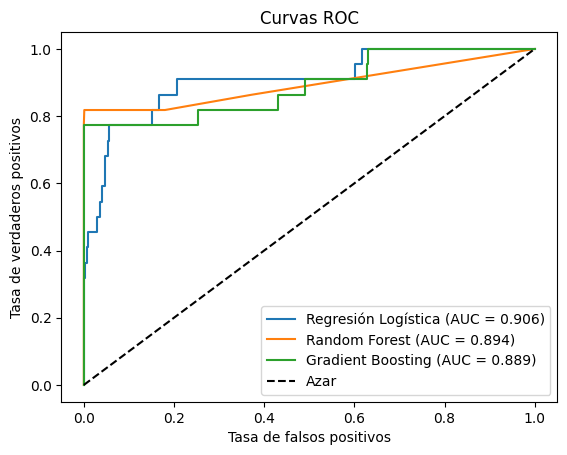

In [ ]:
for nombre, prob in probabilidades.items():
    fpr, tpr, _ = roc_curve(y_test, prob)
    plt.plot(fpr, tpr, label=f'{nombre} (AUC = {roc_auc_score(y_test, prob):.3f})')
plt.plot([0, 1], [0, 1], 'k--', label='Azar')
plt.xlabel('Tasa de falsos positivos'); plt.ylabel('Tasa de verdaderos positivos')
plt.title('Curvas ROC'); plt.legend()
plt.savefig('figuras/curvas_roc.png', bbox_inches='tight')
plt.show()

### 5.3 Clusters en el espacio PCA (por cluster y por es_fraude)

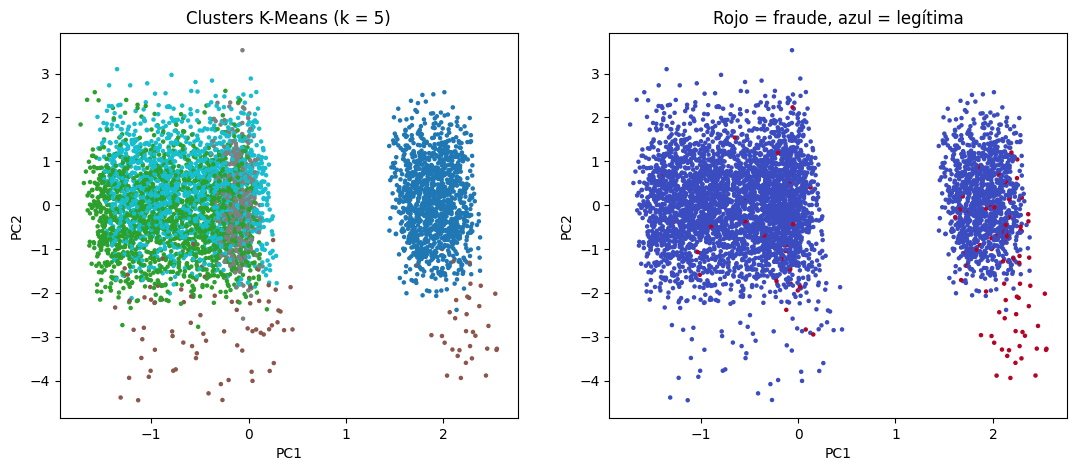

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
ax[0].scatter(X_pca2[:, 0], X_pca2[:, 1], c=df['cluster'], cmap='tab10', s=5)
ax[0].set_title('Clusters K-Means (k = 5)')
ax[1].scatter(X_pca2[:, 0], X_pca2[:, 1], c=df['es_fraude'], cmap='coolwarm', s=5)
ax[1].set_title('Rojo = fraude, azul = legítima')
for a in ax: a.set_xlabel('PC1'); a.set_ylabel('PC2')
plt.savefig('figuras/pca_clusters.png', bbox_inches='tight')
plt.show()

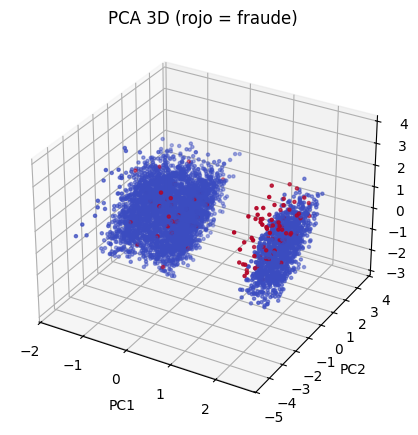

In [ ]:
# Vista 3d para una perspectiva diferente de los clusters
ax = plt.figure(figsize=(7, 5)).add_subplot(projection='3d')
ax.scatter(X_pca3[:, 0], X_pca3[:, 1], X_pca3[:, 2], c=df['es_fraude'], cmap='coolwarm', s=5)
ax.set_xlabel('PC1'); ax.set_ylabel('PC2'); ax.set_zlabel('PC3')
ax.set_title('PCA 3D (rojo = fraude)')
plt.show()

Los fraudes se concentran en una zona (montos altos y noche) y coinciden con los clusters de más riesgo.

### 5.4 Importancia de variables del Random Forest (top 10)

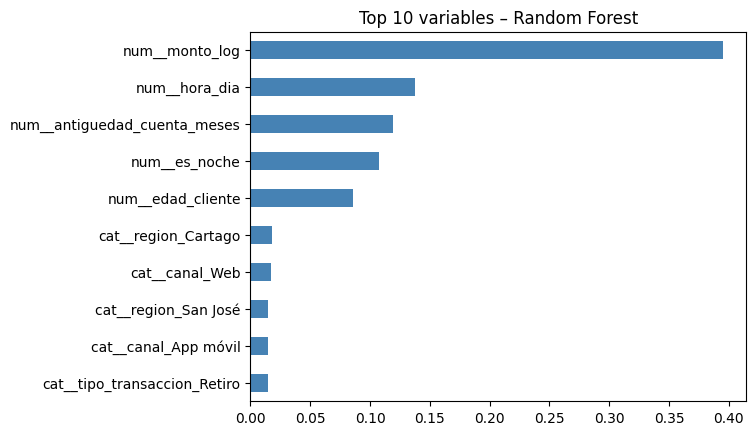

In [ ]:
nombres = rf_pipe.named_steps['preprocesamiento'].get_feature_names_out()
importancia = pd.Series(rf_pipe.named_steps['modelo'].feature_importances_, index=nombres)
top10 = importancia.sort_values().tail(10)                     # las 10 más importantes

top10.plot(kind='barh', color='steelblue')
plt.title('Top 10 variables – Random Forest')
plt.savefig('figuras/importancia_rf.png', bbox_inches='tight')
plt.show()

'monto_log' es por mucho la más importante, seguida de las de horario como 'hora_dia' y 'es_noche'.

### 5.5 Que umbral usar?
El modelo da una probabilidad pero probamos varios umbrales para ver cuántos clientes legitimos molestariamos.

In [ ]:
prob_rf = probabilidades['Random Forest']
for umbral in [0.1, 0.2, 0.3, 0.4, 0.5]:
    tn, fp, fn, tp = confusion_matrix(y_test, (prob_rf >= umbral).astype(int)).ravel()
    print(f'Umbral {umbral}: fraudes detectados = {tp} de {tp + fn} | clientes legítimos molestados = {fp}')

Umbral 0.1: fraudes detectados = 18 de 22 | clientes legítimos molestados = 15
Umbral 0.2: fraudes detectados = 18 de 22 | clientes legítimos molestados = 3
Umbral 0.3: fraudes detectados = 18 de 22 | clientes legítimos molestados = 1
Umbral 0.4: fraudes detectados = 17 de 22 | clientes legítimos molestados = 0
Umbral 0.5: fraudes detectados = 17 de 22 | clientes legítimos molestados = 0


In [ ]:
# Propuesta de 3 niveles de riesgo
nivel = pd.cut(prob_rf, bins=[-0.01, 0.3, 0.5, 1], labels=['Bajo: aprobar', 'Medio: pedir OTP', 'Alto: bloquear'])
pd.crosstab(nivel, y_test.values, rownames=['nivel'], colnames=['es_fraude'], margins=True)

es_fraude,0,1,All
nivel,,,
Bajo: aprobar,977,4,981
Medio: pedir OTP,1,2,3
Alto: bloquear,0,16,16
All,978,22,1000


Con el umbral de 0.3 detectamos 18 de 22 fraudes molestando solo a 1 cliente legitimo, y con 0.5 detectamos 17 sin molestar a ninguno. Bajar el umbral a 0.1 no atrapa más fraudes y si molesta a más clientes.

Con los 3 niveles: 981 transacciones se aprueban sin molestar aunque pasan algunos fraudes, 3 piden OTP los cuales 2 son fraude y 16 se bloquean, y las 16 son fraude real.

### 5.6 Dashboard (4 gráficos)

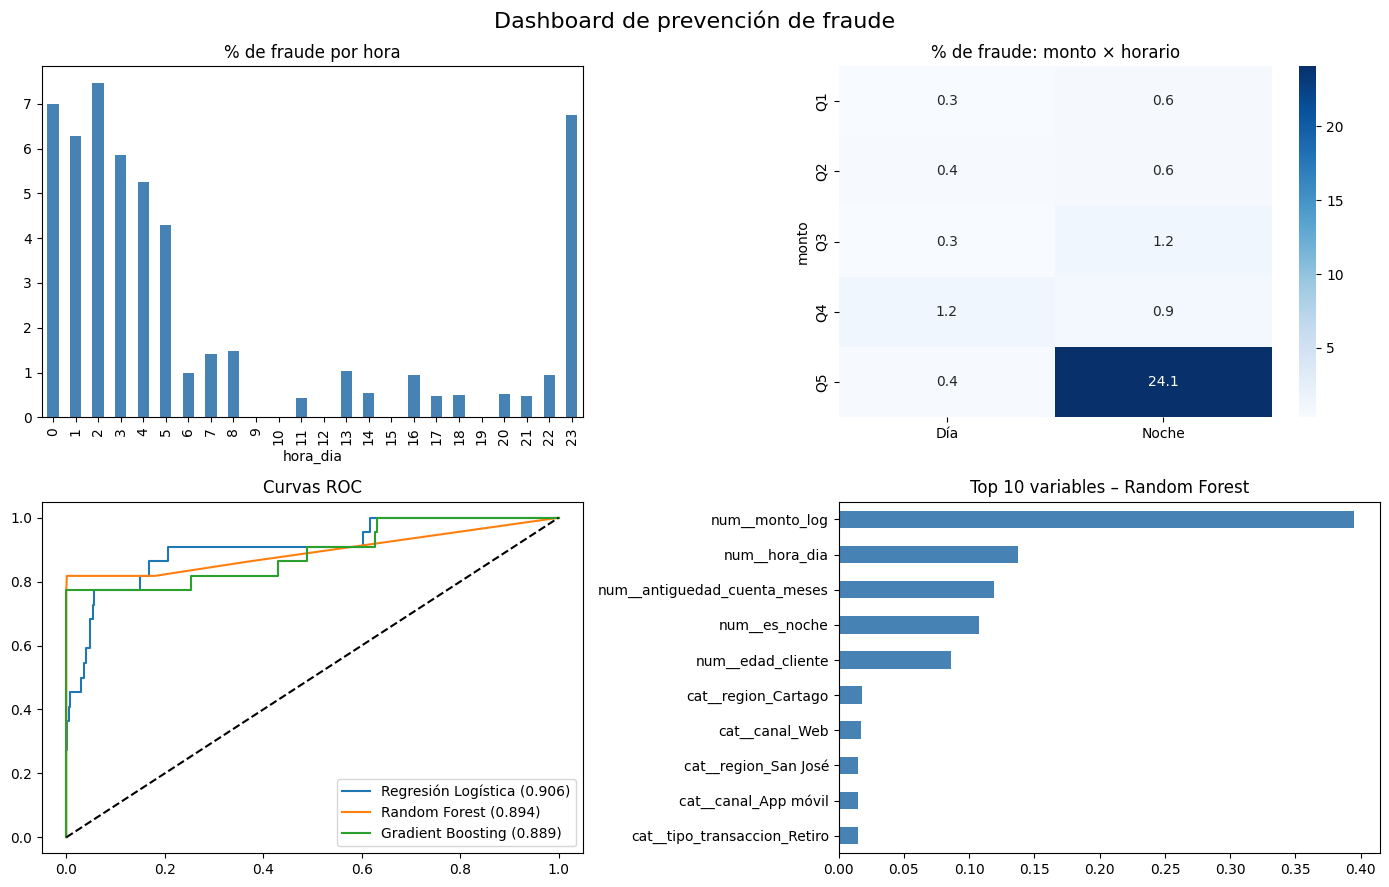

In [ ]:
fig, ax = plt.subplots(2, 2, figsize=(14, 9))
fig.suptitle('Dashboard de prevención de fraude', fontsize=16)

fraude_hora.plot(kind='bar', ax=ax[0, 0], color='steelblue')
ax[0, 0].set_title('% de fraude por hora')

sns.heatmap(tabla, annot=True, fmt='.1f', cmap='Blues', ax=ax[0, 1])
ax[0, 1].set_title('% de fraude: monto × horario')

for nombre, prob in probabilidades.items():
    fpr, tpr, _ = roc_curve(y_test, prob)
    ax[1, 0].plot(fpr, tpr, label=f'{nombre} ({roc_auc_score(y_test, prob):.3f})')
ax[1, 0].plot([0, 1], [0, 1], 'k--'); ax[1, 0].legend(); ax[1, 0].set_title('Curvas ROC')

top10.plot(kind='barh', ax=ax[1, 1], color='steelblue')
ax[1, 1].set_title('Top 10 variables – Random Forest')

plt.tight_layout()
plt.savefig('figuras/dashboard.png', bbox_inches='tight')
plt.show()

---
# Conclusiones
**Que patrones distinguen el fraude?** El **monto alto y la hora de noche/es_noche**, los outliers de monto tienen aprox. 22 veces más fraude, y K-Means, Apriori y el Random Forest llegan a la misma conclusion. edad, antigüedad, canal y región casi no influyen.

**Como usarlo sin molestar al cliente?** Con el Random Forest (que tiene una precision 100% y recall de 73% con el umbral normal, que sube a 82% con umbral 0.3) y tres niveles de riesgo: aprobar, pedir OTP o bloquear. Estas caracteristicas del modelo ayudan a que lleve un proceso de analisis que no involucre al cliente a menos que sea necesario.

**Limitaciones:** los datos son sinteticos, hay solo 22 fraudes en el test (las metricas pueden variar mucho) y 4 fraudes no siguen ningún patrón visible, para detectarlos harían falta datos del historial del cliente o un proceso diferente sobre estos fraudes.